### feature scaling:
types of feature scaling
1. standardization
2. normalization

#z-score normalization/standardization
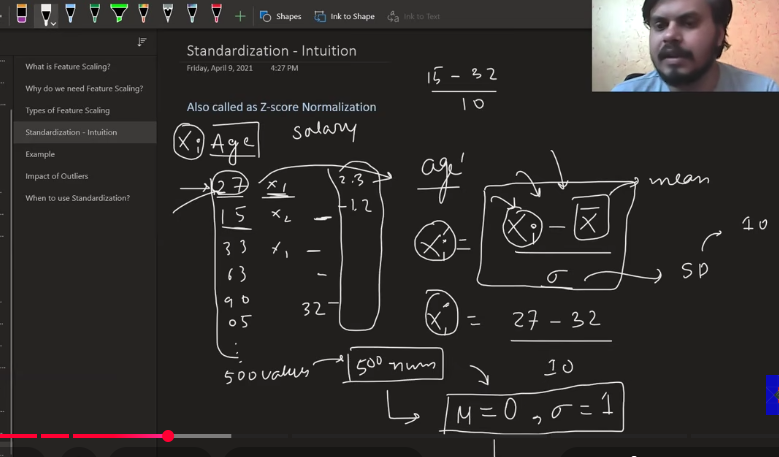

>Mean always 1 and standard deviation always 0
>In standarization we do 2 things either scale up or scale down if mean is greater than 1 than we scale down else scale up
---

**example code**


In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("/home/raghav/ML(100dayseries)/100-days-of-ml-campusx/feature_engineering/Social_Network_Ads.csv")

In [12]:
df = df.iloc[:,2:5] #only keeping the column we need to scale down

In [13]:
df.sample(5)

,Age,EstimatedSalary,Purchased
94,29,83000,0
369,54,26000,1
295,36,63000,0
373,59,130000,1
393,60,42000,1


## **Train Test Split**

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test,Y_train, Y_test = train_test_split( df.drop('Purchased',axis=1),#removing purshased
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)

In [21]:
X_test.shape , X_train.shape

((120, 2), (280, 2))

## **StandardScalar**

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#fit the data to learn the parameters like mean std
scaler.fit(X_train)

#transform both train and test
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [31]:
scaler.var_

array([1.04038724e+02, 1.19572709e+09])

In [35]:
X_train_scaled=pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled=pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [39]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [42]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


In [43]:
np.round(X_test_scaled.describe(),1)

,Age,EstimatedSalary
count,120.0,120.0
mean,-0.1,-0.0
std,1.1,1.0
min,-1.9,-1.6
25%,-1.0,-0.7
50%,-0.2,-0.2
75%,0.7,0.5
max,2.2,2.3


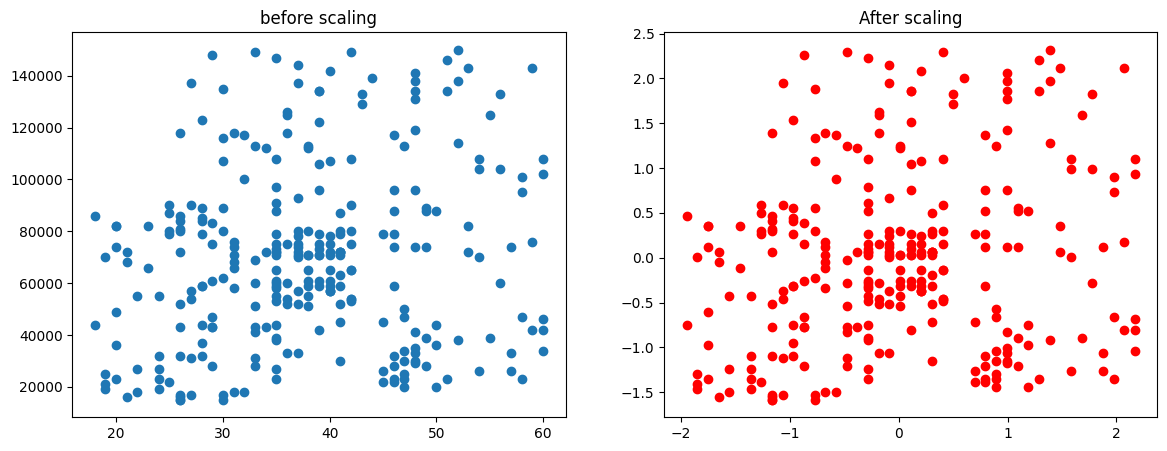

In [47]:
fig,(ax1, ax2)= plt.subplots(ncols=2,figsize=(14,5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("before scaling")

ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("After scaling")
plt.show()